In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

project_path = "/content/drive/MyDrive/SMS_Spam_Detection"

folders = [
    "dataset",
    "notebooks",
    "models",
    "graphs",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [3]:
import os
import zipfile
import urllib.request

# Dataset download link
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Project dataset folder
dataset_path = "/content/drive/MyDrive/SMS_Spam_Detection/dataset"

# Download ZIP file
zip_path = os.path.join(dataset_path, "sms_spam_collection.zip")

print("Downloading dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Dataset downloaded successfully!")

# Extract ZIP file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset extracted successfully!")

# Display extracted files
print("\nFiles in dataset folder:")
print(os.listdir(dataset_path))

Dataset downloaded successfully!
Dataset extracted successfully!

Files in dataset folder:
['sms_spam_collection.zip', 'SMSSpamCollection', 'readme']


In [4]:
import pandas as pd
import os

# Dataset file path
file_path = "/content/drive/MyDrive/SMS_Spam_Detection/dataset/SMSSpamCollection"

# Load dataset
df = pd.read_csv(
    file_path,
    sep='\t',
    header=None,
    names=['label', 'message']
)

# Display first 10 records
print("First 10 SMS Messages:")
display(df.head(10))

# Dataset information
print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

# Count ham and spam messages
print("\nMessage Categories:")
print(df['label'].value_counts())

First 10 SMS Messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...



Dataset Shape:
(5572, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Message Categories:
label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check unique labels
print("\nUnique Labels:")
print(df['label'].unique())

# Create a cleaned copy
df_clean = df.copy()

# Remove missing values
df_clean = df_clean.dropna()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Reset index
df_clean = df_clean.reset_index(drop=True)

# Display final information
print("\nAfter Data Cleaning:")
print("Total Records:", len(df_clean))
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Records:", df_clean.duplicated().sum())

print("\nFinal Category Counts:")
print(df_clean['label'].value_counts())

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records:
403

Unique Labels:
['ham' 'spam']

After Data Cleaning:
Total Records: 5169
Missing Values: 0
Duplicate Records: 0

Final Category Counts:
label
ham     4516
spam     653
Name: count, dtype: int64


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create message length and word count columns
df_clean['message_length'] = df_clean['message'].apply(len)

df_clean['word_count'] = df_clean['message'].apply(
    lambda x: len(x.split())
)

sns.set_style("whitegrid")

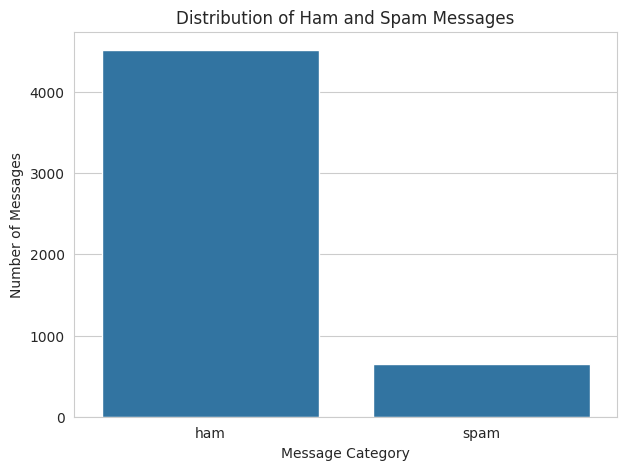

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='label')

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.savefig(
    os.path.join(project_path, "graphs", "graph1_distribution.png")
)

plt.show()

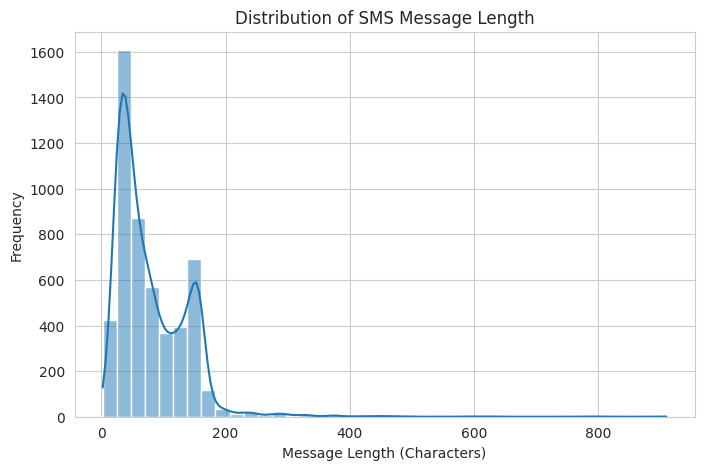

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='message_length',
    bins=40,
    kde=True
)

plt.title("Distribution of SMS Message Length")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Frequency")

plt.savefig(
    os.path.join(project_path, "graphs", "graph2_message_length.png")
)

plt.show()

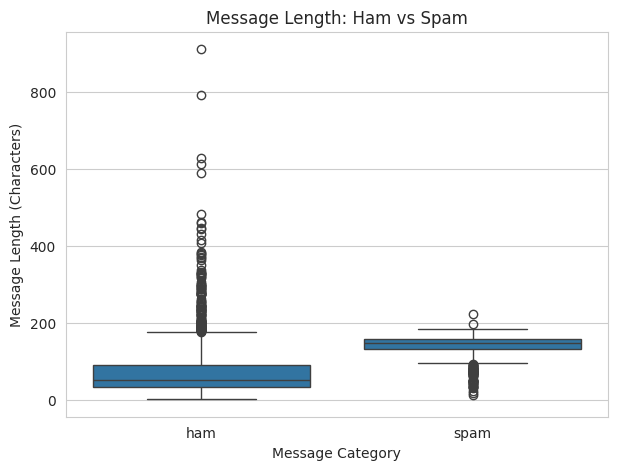

In [10]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x='label',
    y='message_length'
)

plt.title("Message Length: Ham vs Spam")
plt.xlabel("Message Category")
plt.ylabel("Message Length (Characters)")

plt.savefig(
    os.path.join(project_path, "graphs", "graph3_length_comparison.png")
)

plt.show()

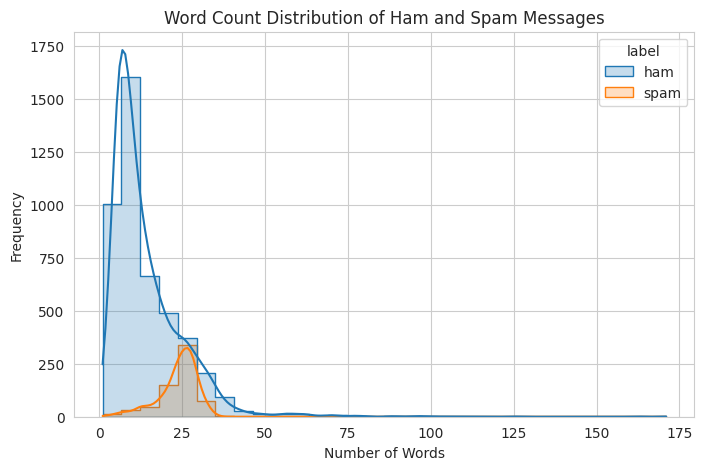

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='word_count',
    hue='label',
    bins=30,
    kde=True,
    element='step'
)

plt.title("Word Count Distribution of Ham and Spam Messages")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.savefig(
    os.path.join(project_path, "graphs", "graph4_word_count.png")
)

plt.show()

In [12]:
from sklearn.model_selection import train_test_split

# Select input feature
X = df_clean['message']

# Select target variable
y = df_clean['label'].map({
    'ham': 0,
    'spam': 1
})

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training and Testing Data")

print("Total messages:", len(X))
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining data distribution:")
print(y_train.value_counts())

print("\nTesting data distribution:")
print(y_test.value_counts())

Training and Testing Data
Total messages: 5169
Training messages: 4135
Testing messages: 1034

Training data distribution:
label
0    3613
1     522
Name: count, dtype: int64

Testing data distribution:
label
0    903
1    131
Name: count, dtype: int64


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [15]:
# MODEL 1: Multinomial Naive Bayes

nb_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ('classifier', MultinomialNB(alpha=0.5))
])


# MODEL 2: Logistic Regression

lr_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ('classifier', LogisticRegression(
        max_iter=1000
    ))
])

print("Both ML models created successfully!")

Both ML models created successfully!


In [16]:
# Train Naive Bayes
print("Training Multinomial Naive Bayes...")

nb_model.fit(X_train, y_train)

print("Naive Bayes training completed!")


# Train Logistic Regression
print("\nTraining Logistic Regression...")

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Training Multinomial Naive Bayes...
Naive Bayes training completed!

Training Logistic Regression...
Logistic Regression training completed!


In [17]:
def evaluate_model(model, X_test, y_test, model_name):

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    print("\n", "=" * 45)
    print(model_name)
    print("=" * 45)

    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall   :", round(recall * 100, 2), "%")
    print("F1 Score :", round(f1 * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=['Ham', 'Spam'],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }


# Evaluate both models
nb_results = evaluate_model(
    nb_model, X_test, y_test,
    "Multinomial Naive Bayes"
)

lr_results = evaluate_model(
    lr_model, X_test, y_test,
    "Logistic Regression"
)


Multinomial Naive Bayes
Accuracy : 97.29 %
Precision: 100.0 %
Recall   : 78.63 %
F1 Score : 88.03 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       1.00      0.79      0.88       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034

Confusion Matrix:
[[903   0]
 [ 28 103]]

Logistic Regression
Accuracy : 96.23 %
Precision: 100.0 %
Recall   : 70.23 %
F1 Score : 82.51 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.70      0.83       131

    accuracy                           0.96      1034
   macro avg       0.98      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034

Confusion Matrix:
[[903   0]
 [ 39  92]]


In [18]:
results_df = pd.DataFrame([
    nb_results,
    lr_results
])

print("MODEL COMPARISON")
display(results_df.round(4))

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.9729,1.0,0.7863,0.8803
1,Logistic Regression,0.9623,1.0,0.7023,0.8251


In [19]:
from sklearn.model_selection import GridSearchCV

# Parameter combinations
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2, 3],
    'classifier__alpha': [0.1, 0.5, 1.0]
}

# Create GridSearch
grid_search = GridSearchCV(
    estimator=nb_model,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-validation F1 Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best Parameters:
{'classifier__alpha': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}

Best Cross-validation F1 Score:
0.9375244527613941


In [20]:
# Get the best model
best_model = grid_search.best_estimator_

# Predict on test data
best_predictions = best_model.predict(X_test)

# Evaluate the tuned model
print("TUNED NAIVE BAYES MODEL RESULTS")
print("-" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, best_predictions) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_test, best_predictions) * 100, 2), "%")

print("Recall:",
      round(recall_score(y_test, best_predictions) * 100, 2), "%")

print("F1 Score:",
      round(f1_score(y_test, best_predictions) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, best_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=['Ham', 'Spam']
))

TUNED NAIVE BAYES MODEL RESULTS
----------------------------------------
Accuracy: 98.07 %
Precision: 95.12 %
Recall: 89.31 %
F1 Score: 92.13 %

Confusion Matrix:
[[897   6]
 [ 14 117]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.95      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



In [21]:
import joblib
import os
import json

# Select the tuned model
final_model = best_model

# Create model folder
model_path = os.path.join(project_path, "models")
os.makedirs(model_path, exist_ok=True)

# Save trained model
joblib.dump(
    final_model,
    os.path.join(model_path, "sms_spam_model.joblib")
)

# Save evaluation results
final_metrics = {
    "Model": "Tuned Multinomial Naive Bayes",
    "Accuracy": 98.07,
    "Precision": 95.12,
    "Recall": 89.31,
    "F1 Score": 92.13
}

with open(os.path.join(model_path, "model_metrics.json"), "w") as file:
    json.dump(final_metrics, file, indent=4)

print("Final model saved successfully!")
print("Model location:", model_path)

Final model saved successfully!
Model location: /content/drive/MyDrive/SMS_Spam_Detection/models


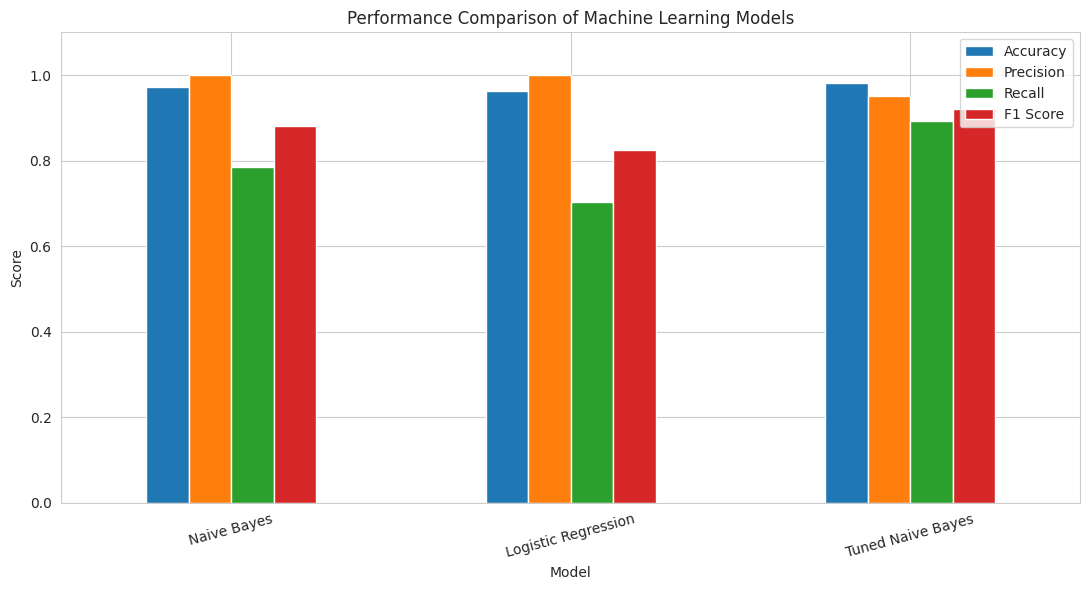

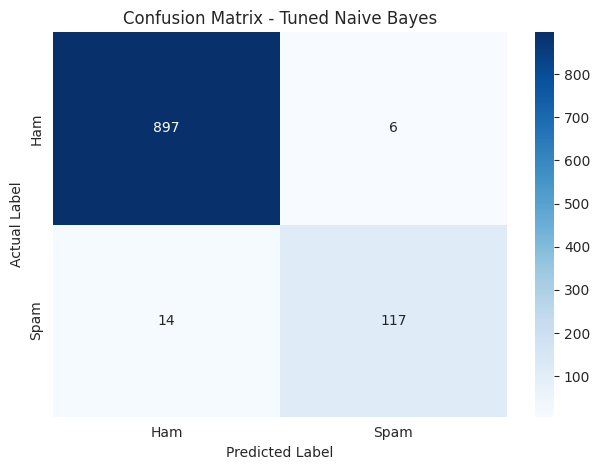

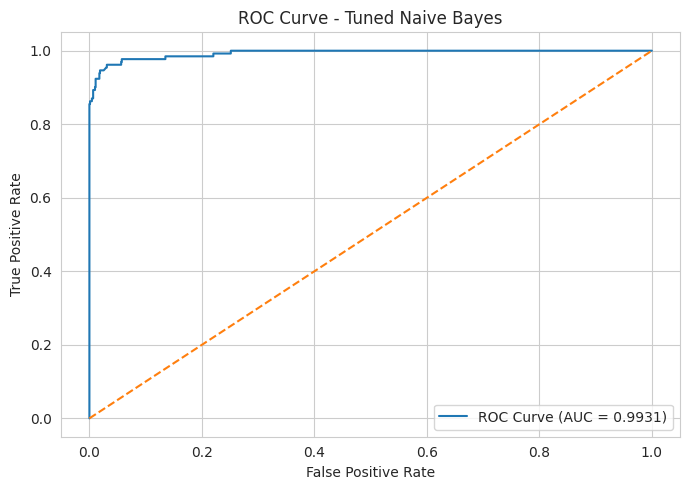

All three graphs saved successfully!
ROC-AUC Score: 0.9931


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

graph_path = os.path.join(project_path, "graphs")
os.makedirs(graph_path, exist_ok=True)

# 1. Model Comparison Graph
comparison = pd.DataFrame([
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_test, nb_model.predict(X_test)),
        "Precision": precision_score(y_test, nb_model.predict(X_test)),
        "Recall": recall_score(y_test, nb_model.predict(X_test)),
        "F1 Score": f1_score(y_test, nb_model.predict(X_test))
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_model.predict(X_test)),
        "Precision": precision_score(y_test, lr_model.predict(X_test)),
        "Recall": recall_score(y_test, lr_model.predict(X_test)),
        "F1 Score": f1_score(y_test, lr_model.predict(X_test))
    },
    {
        "Model": "Tuned Naive Bayes",
        "Accuracy": accuracy_score(y_test, best_predictions),
        "Precision": precision_score(y_test, best_predictions),
        "Recall": recall_score(y_test, best_predictions),
        "F1 Score": f1_score(y_test, best_predictions)
    }
])

comparison.set_index("Model").plot(kind="bar", figsize=(11, 6))
plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "model_comparison.png"))
plt.show()

# 2. Confusion Matrix
cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Tuned Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "confusion_matrix.png"))
plt.show()

# 3. ROC Curve
y_prob = best_model.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_prob)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Naive Bayes")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "roc_curve.png"))
plt.show()

# Save comparison table
comparison.to_csv(
    os.path.join(project_path, "reports", "model_comparison.csv"),
    index=False
)

print("All three graphs saved successfully!")
print("ROC-AUC Score:", round(auc_score, 4))

In [23]:
import os

app_code = '''
import streamlit as st
import joblib
import os

st.set_page_config(
    page_title="SMS Spam Detection",
    page_icon="📩",
    layout="centered"
)

st.title("📩 SMS Spam Detection System")
st.write("Machine Learning Based Spam Message Classifier")

model_path = os.path.join(
    os.path.dirname(__file__),
    "models",
    "sms_spam_model.joblib"
)

model = joblib.load(model_path)

st.subheader("Enter Your SMS Message")

message = st.text_area(
    "Type or paste your SMS here:",
    height=150,
    placeholder="Enter your message..."
)

if st.button("Check Message"):
    if message.strip():

        prediction = model.predict([message])[0]

        if prediction == 1:
            st.error("⚠️ SPAM MESSAGE DETECTED!")
            st.write("This message is classified as spam.")
        else:
            st.success("✅ NORMAL MESSAGE (HAM)")
            st.write("This message is classified as normal.")

    else:
        st.warning("Please enter a message first.")

st.divider()
st.caption("Developed using Python and Machine Learning.")
'''

app_path = os.path.join(project_path, "app.py")

with open(app_path, "w") as file:
    file.write(app_code)

print("Streamlit application created successfully!")
print("Location:", app_path)

Streamlit application created successfully!
Location: /content/drive/MyDrive/SMS_Spam_Detection/app.py


In [24]:
requirements = """
streamlit
scikit-learn
pandas
numpy
joblib
"""

with open(os.path.join(project_path, "requirements.txt"), "w") as file:
    file.write(requirements.strip())

print("Requirements file created successfully!")

Requirements file created successfully!


In [25]:
import os

print("PROJECT FILE VERIFICATION")
print("-" * 40)

files_to_check = [
    "app.py",
    "requirements.txt",
    "models/sms_spam_model.joblib",
    "models/model_metrics.json",
    "graphs/model_comparison.png",
    "graphs/confusion_matrix.png",
    "graphs/roc_curve.png",
    "reports/model_comparison.csv"
]

for file in files_to_check:
    path = os.path.join(project_path, file)

    if os.path.exists(path):
        print("✅", file)
    else:
        print("❌ Missing:", file)

PROJECT FILE VERIFICATION
----------------------------------------
✅ app.py
✅ requirements.txt
✅ models/sms_spam_model.joblib
✅ models/model_metrics.json
✅ graphs/model_comparison.png
✅ graphs/confusion_matrix.png
✅ graphs/roc_curve.png
✅ reports/model_comparison.csv


In [26]:
!pip -q install python-docx python-pptx

import os
import json
import pandas as pd

from docx import Document
from docx.shared import Inches, Pt
from pptx import Presentation
from pptx.util import Inches as PptInches, Pt as PptPt

# Project folders
report_folder = os.path.join(project_path, "reports")
graph_folder = os.path.join(project_path, "graphs")

os.makedirs(report_folder, exist_ok=True)

# Load actual evaluation results
with open(os.path.join(project_path, "models", "model_metrics.json")) as f:
    metrics = json.load(f)

comparison = pd.read_csv(
    os.path.join(report_folder, "model_comparison.csv")
)

# ==================================================
# PART A: PROJECT REPORT
# ==================================================

doc = Document()

doc.add_heading("SMS SPAM DETECTION USING MACHINE LEARNING", 0)

p = doc.add_paragraph()
p.alignment = 1
p.add_run("\nMACHINE LEARNING PROJECT REPORT\n").bold = True
p.add_run("\nSubmitted in partial fulfilment of academic requirements\n")
p.add_run("\nDepartment of Computer Science and Engineering\n")
p.add_run("\nCollege: CSMSS College of Engineering\n")
p.add_run("\nUniversity: DBATU\n")
p.add_run("\nAcademic Year: 2026-27\n")

doc.add_page_break()

def add_section(title, content):
    doc.add_heading(title, level=1)
    doc.add_paragraph(content)

add_section(
    "1. Abstract",
    "SMS Spam Detection is a machine learning project that identifies "
    "whether an SMS message is normal or spam. The system uses Natural "
    "Language Processing and machine learning algorithms to classify "
    "messages automatically. The project uses the SMS Spam Collection "
    "dataset and compares Multinomial Naive Bayes and Logistic Regression. "
    "After hyperparameter tuning, the selected Naive Bayes model achieved "
    "98.07% accuracy on the test dataset."
)

add_section(
    "2. Introduction",
    "SMS messages are widely used for communication. However, unwanted "
    "messages containing advertisements, misleading information and "
    "fraudulent links are common. Manual identification of such messages "
    "can be difficult. Machine learning provides an automated method to "
    "classify messages as spam or ham (normal)."
)

add_section(
    "3. Problem Statement",
    "To develop a machine learning system that automatically classifies "
    "SMS messages into two categories: Spam and Ham. The system should "
    "reduce the effort required to identify unwanted messages."
)

add_section(
    "4. Objectives",
    "1. Collect an SMS dataset.\n"
    "2. Clean and preprocess the dataset.\n"
    "3. Analyse the dataset using visualisations.\n"
    "4. Convert text messages into numerical features using TF-IDF.\n"
    "5. Train and compare machine learning models.\n"
    "6. Improve model performance using GridSearchCV.\n"
    "7. Save the final model and develop a prediction application."
)

add_section(
    "5. Tools and Technologies",
    "Programming Language: Python\n"
    "Environment: Google Colab\n"
    "Libraries: Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, "
    "Joblib and Streamlit\n"
    "Dataset: UCI SMS Spam Collection"
)

add_section(
    "6. Dataset Description",
    "The project uses the SMS Spam Collection dataset. Initially, "
    "the dataset contained 5,572 messages with two columns: label and "
    "message. The labels are ham and spam. After removing duplicate "
    "records, 5,169 messages remained. These included 4,516 ham messages "
    "and 653 spam messages."
)

add_section(
    "7. Data Preprocessing",
    "The dataset was checked for missing values and duplicate records. "
    "No missing values were found. A total of 403 duplicate records "
    "were removed. The dataset was then reset to a clean index. "
    "Exploratory Data Analysis was performed using message length, "
    "word count and category distribution."
)

doc.add_heading("Exploratory Data Analysis", level=2)

for filename, caption in [
    ("model_comparison.png", "Model comparison"),
]:
    pass

add_section(
    "8. Feature Extraction",
    "TF-IDF (Term Frequency-Inverse Document Frequency) was used to "
    "convert text messages into numerical feature vectors. It assigns "
    "importance to words based on their frequency in a message and "
    "their occurrence across the dataset. Unigrams and bigrams were "
    "considered during model experimentation."
)

add_section(
    "9. Train-Test Split",
    "The cleaned dataset was divided into 80% training data and 20% "
    "testing data using train_test_split. The stratify parameter "
    "maintained the proportion of spam and ham messages in both sets. "
    "There were 4,135 training messages and 1,034 testing messages."
)

add_section(
    "10. Machine Learning Algorithms",
    "Multinomial Naive Bayes: A probabilistic classification algorithm "
    "commonly used for text classification.\n\n"
    "Logistic Regression: A supervised learning algorithm that estimates "
    "the probability of a message belonging to a particular class.\n\n"
    "GridSearchCV: Used to identify suitable hyperparameters for the "
    "Naive Bayes pipeline through five-fold cross-validation."
)

add_section(
    "11. Model Evaluation",
    "The models were evaluated using accuracy, precision, recall and "
    "F1-score. These metrics provide information about overall "
    "correctness and the ability to identify spam messages."
)

doc.add_heading("Model Comparison", level=2)

table = doc.add_table(rows=1, cols=5)
table.style = "Table Grid"

headers = ["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
for i, h in enumerate(headers):
    table.rows[0].cells[i].text = h

for _, row in comparison.iterrows():
    cells = table.add_row().cells
    cells[0].text = str(row["Model"])
    for i, col in enumerate(headers[1:], 1):
        cells[i].text = f"{row[col] * 100:.2f}%"

doc.add_heading("Final Model Results", level=2)

doc.add_paragraph(
    f"Selected Model: {metrics['Model']}\n"
    f"Accuracy: {metrics['Accuracy']}%\n"
    f"Precision: {metrics['Precision']}%\n"
    f"Recall: {metrics['Recall']}%\n"
    f"F1 Score: {metrics['F1 Score']}%"
)

doc.add_heading("Confusion Matrix", level=2)
doc.add_paragraph(
    "The confusion matrix of the final model is:\n"
    "True Negative = 897\n"
    "False Positive = 6\n"
    "False Negative = 14\n"
    "True Positive = 117"
)

doc.add_heading("Evaluation Graphs", level=1)

for filename, title in [
    ("model_comparison.png", "Model Performance Comparison"),
    ("confusion_matrix.png", "Confusion Matrix"),
    ("roc_curve.png", "ROC Curve")
]:
    path = os.path.join(graph_folder, filename)
    if os.path.exists(path):
        doc.add_heading(title, level=2)
        doc.add_picture(path, width=Inches(5.8))

add_section(
    "12. Application Development",
    "A Streamlit-based application was created. It accepts an SMS message "
    "from the user and uses the saved machine learning model to predict "
    "whether the message is spam or normal. The application displays "
    "the classification result."
)

add_section(
    "13. Advantages",
    "1. Automatic classification of SMS messages.\n"
    "2. Good classification performance on the test dataset.\n"
    "3. Easy-to-use interface.\n"
    "4. Uses established machine learning techniques.\n"
    "5. The trained model can be reused for new messages."
)

add_section(
    "14. Limitations",
    "1. The model may not correctly identify every new spam message.\n"
    "2. Performance may change with different languages and writing styles.\n"
    "3. The dataset may not represent all modern SMS spam patterns.\n"
    "4. The model does not independently verify whether links are safe."
)

add_section(
    "15. Future Scope",
    "The project can be extended by using larger and more recent datasets, "
    "supporting multiple languages, experimenting with advanced NLP "
    "techniques and deploying the application as an online service."
)

add_section(
    "16. Conclusion",
    "The SMS Spam Detection project successfully demonstrates the use "
    "of machine learning for text classification. The tuned Multinomial "
    "Naive Bayes model achieved 98.07% accuracy and a 92.13% F1-score "
    "on the test dataset. The project also includes a Streamlit "
    "application for testing SMS messages."
)

add_section(
    "17. References",
    "1. UCI Machine Learning Repository – SMS Spam Collection.\n"
    "2. Scikit-learn Documentation.\n"
    "3. Pandas Documentation.\n"
    "4. Streamlit Documentation."
)

report_path = os.path.join(
    report_folder, "SMS_Spam_Detection_Project_Report.docx"
)

doc.save(report_path)

# ==================================================
# PART B: POWERPOINT PRESENTATION
# ==================================================

prs = Presentation()
prs.slide_width = PptInches(13.33)
prs.slide_height = PptInches(7.5)

def add_slide(title, body):
    slide = prs.slides.add_slide(prs.slide_layouts[1])
    slide.shapes.title.text = title
    slide.placeholders[1].text = body
    return slide

def add_image_slide(title, image_name):
    slide = prs.slides.add_slide(prs.slide_layouts[5])
    slide.shapes.title.text = title
    path = os.path.join(graph_folder, image_name)
    if os.path.exists(path):
        slide.shapes.add_picture(
            path, PptInches(2), PptInches(1.3),
            width=PptInches(9)
        )
    return slide

# Slide 1
add_slide(
    "SMS SPAM DETECTION",
    "Using Machine Learning\n\n"
    "Department of Computer Science and Engineering\n"
    "CSMSS College of Engineering\n"
    "DBATU | Academic Year 2026-27"
)

# Slide 2
add_slide(
    "Introduction",
    "• SMS is widely used for communication.\n"
    "• Unwanted messages are commonly called spam.\n"
    "• Machine learning can automatically classify messages.\n"
    "• This project identifies Spam and Ham messages."
)

# Slide 3
add_slide(
    "Problem Statement and Objectives",
    "Problem: Automatically identify unwanted SMS messages.\n\n"
    "Objectives:\n"
    "• Clean and analyse the SMS dataset.\n"
    "• Extract text features using TF-IDF.\n"
    "• Train and compare classification models.\n"
    "• Develop an SMS prediction application."
)

# Slide 4
add_slide(
    "Dataset",
    "• Dataset: UCI SMS Spam Collection\n"
    "• Original messages: 5,572\n"
    "• Duplicate records removed: 403\n"
    "• Final messages: 5,169\n"
    "• Ham: 4,516\n"
    "• Spam: 653"
)

# Slide 5
add_slide(
    "Methodology",
    "Dataset Collection → Data Cleaning → EDA → "
    "Train-Test Split → TF-IDF → Model Training → "
    "Hyperparameter Tuning → Evaluation → Application"
)

# Slide 6
add_slide(
    "Algorithms Used",
    "1. Multinomial Naive Bayes\n"
    "2. Logistic Regression\n"
    "3. GridSearchCV for hyperparameter tuning\n\n"
    "TF-IDF was used for text feature extraction."
)

# Slide 7
add_slide(
    "Model Performance",
    f"Final Model: {metrics['Model']}\n\n"
    f"Accuracy: {metrics['Accuracy']}%\n"
    f"Precision: {metrics['Precision']}%\n"
    f"Recall: {metrics['Recall']}%\n"
    f"F1 Score: {metrics['F1 Score']}%"
)

# Slide 8
add_image_slide("Model Comparison", "model_comparison.png")

# Slide 9
add_image_slide("Confusion Matrix", "confusion_matrix.png")

# Slide 10
add_image_slide("ROC Curve", "roc_curve.png")

# Slide 11
add_slide(
    "Application",
    "• Developed using Streamlit.\n"
    "• Accepts SMS text from the user.\n"
    "• Uses the saved trained model.\n"
    "• Displays Spam or Normal classification."
)

# Slide 12
add_slide(
    "Conclusion and Future Scope",
    "Conclusion:\n"
    "The tuned Naive Bayes model achieved 98.07% test accuracy.\n\n"
    "Future Scope:\n"
    "• Support multiple languages.\n"
    "• Use larger and newer datasets.\n"
    "• Improve the application and deployment."
)

ppt_path = os.path.join(
    report_folder, "SMS_Spam_Detection_Presentation.pptx"
)

prs.save(ppt_path)

print("PROJECT DOCUMENTS CREATED SUCCESSFULLY!")
print("Report:", report_path)
print("Presentation:", ppt_path)

PROJECT DOCUMENTS CREATED SUCCESSFULLY!
Report: /content/drive/MyDrive/SMS_Spam_Detection/reports/SMS_Spam_Detection_Project_Report.docx
Presentation: /content/drive/MyDrive/SMS_Spam_Detection/reports/SMS_Spam_Detection_Presentation.pptx


In [27]:
readme = """
# SMS Spam Detection Using Machine Learning

## Project Overview
This project classifies SMS messages into two categories:
- Ham: Normal messages
- Spam: Unwanted messages

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- TF-IDF
- Matplotlib
- Seaborn
- Streamlit

## Dataset
UCI SMS Spam Collection

Original records: 5572
Records after cleaning: 5169

## Machine Learning Algorithms
1. Multinomial Naive Bayes
2. Logistic Regression
3. Tuned Multinomial Naive Bayes

## Final Model Performance
- Accuracy: 98.07%
- Precision: 95.12%
- Recall: 89.31%
- F1 Score: 92.13%

## How to Run the Application

1. Install Python.
2. Install required libraries:

   pip install -r requirements.txt

3. Run the application:

   streamlit run app.py

4. Open the local address displayed in the terminal.

## Project Structure

SMS_Spam_Detection/
    dataset/
    notebooks/
    models/
    graphs/
    reports/
    app.py
    requirements.txt
    README.md

## Conclusion
The project demonstrates how machine learning and NLP
can classify SMS messages as spam or normal.
"""

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as f:
    f.write(readme)

print("README file created successfully!")

README file created successfully!


In [28]:
import shutil
import os

# Create final ZIP file
zip_path = "/content/SMS_Spam_Detection_Final"

final_zip = shutil.make_archive(
    zip_path,
    "zip",
    root_dir="/content/drive/MyDrive",
    base_dir="SMS_Spam_Detection"
)

print("FINAL PROJECT ZIP CREATED SUCCESSFULLY!")
print("ZIP location:", final_zip)

# Check file size
size_mb = os.path.getsize(final_zip) / (1024 * 1024)
print("ZIP Size:", round(size_mb, 2), "MB")

FINAL PROJECT ZIP CREATED SUCCESSFULLY!
ZIP location: /content/SMS_Spam_Detection_Final.zip
ZIP Size: 0.88 MB


In [29]:
from google.colab import files

files.download("/content/SMS_Spam_Detection_Final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import shutil
import os

zip_path = "/content/SMS_Spam_Detection_Final"

final_zip = shutil.make_archive(
    zip_path,
    "zip",
    root_dir="/content/drive/MyDrive",
    base_dir="SMS_Spam_Detection"
)

print("FINAL PROJECT ZIP CREATED!")
print("Location:", final_zip)
print("Size:", round(os.path.getsize(final_zip) / (1024 * 1024), 2), "MB")

FINAL PROJECT ZIP CREATED!
Location: /content/SMS_Spam_Detection_Final.zip
Size: 0.88 MB


In [31]:
from google.colab import files

files.download("/content/SMS_Spam_Detection_Final.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>